In [1]:
%pip install torch torchvision pandas numpy scikit-learn matplotlib opencv-python tqdm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import random
import gc
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from tqdm.auto import tqdm

from sklearn.metrics import (
    f1_score,
    accuracy_score,
    classification_report,
    confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

C:\Users\Dell\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cuda


In [3]:
DATASET_ROOT = Path(r"C:\Users\Dell\Downloads\DAiSEE\DAiSEE")
LABEL_DIR = DATASET_ROOT / "Labels"

TRAIN_CSV = LABEL_DIR / "TrainLabels.csv"
VAL_CSV = LABEL_DIR / "ValidationLabels.csv"
TEST_CSV = LABEL_DIR / "TestLabels.csv"


NUM_FRAMES = 8
IMG_SIZE = 112
BATCH_SIZE = 2
NUM_WORKERS = 0

LABELS = [
    "Boredom",
    "Confusion",
    "Engagement",
    "Frustration"
]

CLIP_COLUMN = "ClipID"

for path in [TRAIN_CSV, VAL_CSV, TEST_CSV]:
    print(path.name, "exists:", path.exists())

print("CUDA available:", torch.cuda.is_available())

TrainLabels.csv exists: True
ValidationLabels.csv exists: True
TestLabels.csv exists: True
CUDA available: True


In [4]:
video_extensions = {".avi", ".mp4", ".mov", ".mkv"}
video_index = {}

for path in DATASET_ROOT.rglob("*"):
    if path.is_file() and path.suffix.lower() in video_extensions:
        if path.name in video_index:
            print("Duplicate filename detected:", path.name)
        video_index[path.name] = path

print("Videos indexed:", len(video_index))
print("Examples:", list(video_index.keys())[:5])

Videos indexed: 8829
Examples: ['8263820112.mp4', '8263820113.mp4', '8263820120.mp4', '8263820123.mp4', '8263820124.mp4']


In [5]:
frame_transform = transforms.Compose([
    transforms.ToPILImage(),
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


def load_video_frames(video_path):
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {video_path}")

    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if total_frames <= 0:
        cap.release()
        raise ValueError(f"No readable frames: {video_path}")

    indices = np.linspace(
        0, total_frames - 1, NUM_FRAMES
    ).astype(int)

    frames = []

    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(idx))
        success, frame = cap.read()

        if not success:
            cap.release()
            raise ValueError(
                f"Cannot read frame {idx} from {video_path}"
            )

        frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append(frame_transform(frame))

    cap.release()

    return torch.stack(frames)

In [6]:
class DAiSEEDataset(Dataset):
    def __init__(self, csv_path, video_index):
        self.df = pd.read_csv(csv_path)
        self.df.columns = self.df.columns.str.strip()

        required = [CLIP_COLUMN] + LABELS
        missing = [c for c in required if c not in self.df.columns]

        if missing:
            raise ValueError(
                f"Missing columns: {missing}\n"
                f"Found: {self.df.columns.tolist()}"
            )

        self.df[CLIP_COLUMN] = (
            self.df[CLIP_COLUMN].astype(str).str.strip()
        )

        # Keep only rows whose video files exist
        available = set(video_index.keys())

        self.df = self.df[
            self.df[CLIP_COLUMN].isin(available)
        ].reset_index(drop=True)

        for label in LABELS:
            self.df[label] = pd.to_numeric(
                self.df[label], errors="raise"
            ).astype(int)

            if not self.df[label].between(0, 3).all():
                raise ValueError(
                    f"{label} contains values outside 0–3"
                )

        self.video_index = video_index

        print(
            f"{Path(csv_path).name}: "
            f"{len(self.df)} matched clips"
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        video_path = self.video_index[row[CLIP_COLUMN]]

        frames = load_video_frames(video_path)

        labels = torch.tensor(
            [row[label] for label in LABELS],
            dtype=torch.long
        )

        return frames, labels

In [7]:
train_dataset = DAiSEEDataset(TRAIN_CSV, video_index)
val_dataset = DAiSEEDataset(VAL_CSV, video_index)
test_dataset = DAiSEEDataset(TEST_CSV, video_index)

print("Dataset sizes:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

TrainLabels.csv: 5357 matched clips
ValidationLabels.csv: 1429 matched clips
TestLabels.csv: 1546 matched clips
Dataset sizes:
Train: 5357
Validation: 1429
Test: 1546


In [8]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(device.type == "cuda")
)

videos, labels = next(iter(train_loader))

print("Video shape:", videos.shape)
print("Label shape:", labels.shape)

Video shape: torch.Size([2, 8, 3, 112, 112])
Label shape: torch.Size([2, 4])


In [9]:
class SundayVideoModel(nn.Module):
    def __init__(self, hidden_size=128, dropout=0.3):
        super().__init__()

        backbone = models.efficientnet_b0(
            weights=models.EfficientNet_B0_Weights.DEFAULT
        )

        self.cnn = backbone.features
        self.pool = backbone.avgpool
        self.feature_dim = backbone.classifier[1].in_features

        # Freeze CNN during the first training stage
        for param in self.cnn.parameters():
            param.requires_grad = False

        self.bilstm = nn.LSTM(
            input_size=self.feature_dim,
            hidden_size=hidden_size,
            num_layers=1,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)

        self.heads = nn.ModuleList([
            nn.Linear(hidden_size * 2, 4)
            for _ in LABELS
        ])

    def forward(self, videos):
        batch, time, channels, height, width = videos.shape

        frames = videos.reshape(
            batch * time, channels, height, width
        )

        # Frozen CNN features do not need gradients
        with torch.no_grad():
            features = self.cnn(frames)
            features = self.pool(features)
            features = features.flatten(1)

        features = features.reshape(
            batch, time, self.feature_dim
        )

        sequence, _ = self.bilstm(features)

        # Aggregate temporal information
        representation = self.dropout(sequence.mean(dim=1))

        outputs = torch.stack(
            [head(representation) for head in self.heads],
            dim=1
        )

        return outputs

In [10]:
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

model = SundayVideoModel().to(device)

print("Model:", type(model).__name__)
print("Device:", device)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

Model: SundayVideoModel
Device: cuda
Trainable parameters: 1447952


In [11]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

print("Optimizer: Adam")
print("Learning rate: 0.0001")

Optimizer: Adam
Learning rate: 0.0001


In [12]:
videos, labels = next(iter(train_loader))
videos = videos.to(device)

model.eval()

with torch.no_grad():
    outputs = model(videos)

print("Input:", videos.shape)
print("Output:", outputs.shape)

Input: torch.Size([2, 8, 3, 112, 112])
Output: torch.Size([2, 4, 4])


In [26]:
%pip install tqdm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [13]:
from tqdm.auto import tqdm
import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score,precision_score,recall_score
  


def run_epoch(model, loader, training=False, epoch_num=1, total_epochs=5):

    model.train() if training else model.eval()

    total_loss = 0.0
    all_targets = []
    all_predictions = []

    phase = "Train" if training else "Validation"

    progress = tqdm(
        loader,
        desc=f"{phase} Epoch {epoch_num}/{total_epochs}",
        unit="batch",
        dynamic_ncols=True
    )

    for batch_idx, (videos, targets) in enumerate(progress, start=1):

        videos = videos.to(device)
        targets = targets.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):

            outputs = model(videos)

            loss = torch.stack([
                criterion(outputs[:, i, :], targets[:, i])
                for i in range(len(LABELS))
            ]).mean()

            if training:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )

                optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=2)

        all_targets.extend(
            targets.detach().cpu().numpy().reshape(-1).tolist()
        )

        all_predictions.extend(
            predictions.detach().cpu().numpy().reshape(-1).tolist()
        )

        # Running metrics across all batches processed so far
        running_loss = total_loss / batch_idx

        running_accuracy = accuracy_score(
            all_targets, all_predictions
        )

        # Show live loss and accuracy in the progress bar
        progress.set_postfix({
            "loss": f"{running_loss:.4f}",
            "accuracy": f"{running_accuracy:.4f}"
        })

    if len(loader) == 0:
        raise ValueError(f"{phase} DataLoader contains no batches.")

    epoch_loss = float(total_loss / len(loader))

    accuracy = float(accuracy_score(
        all_targets, all_predictions
    ))

    precision = float(precision_score(
        all_targets,
        all_predictions,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    ))

    recall = float(recall_score(
        all_targets,
        all_predictions,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    ))

    f1 = float(f1_score(
        all_targets,
        all_predictions,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    ))

    return {
        "loss": epoch_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [31]:
import pandas as pd
from pathlib import Path

EPOCHS = 10

OUTPUT_DIR = Path("sunday_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

METRICS_FILE = OUTPUT_DIR / "sunday_training_metrics.csv"
BEST_MODEL_FILE = OUTPUT_DIR / "sunday_cnn_bilstm_adam_best.pt"

history = []
best_val_f1 = -1.0

for epoch in range(1, EPOCHS + 1):

    start_time = time.time()

    print("\n" + "=" * 70)
    print(f"EPOCH {epoch}/{EPOCHS} | Completed: {epoch - 1}/{EPOCHS}")
    print("=" * 70)

    # Training with live progress bar
    train_metrics = run_epoch(
        model,
        train_loader,
        training=True,
        epoch_num=epoch,
        total_epochs=EPOCHS
    )

    # Validation with live progress bar
    val_metrics = run_epoch(
        model,
        val_loader,
        training=False,
        epoch_num=epoch,
        total_epochs=EPOCHS
    )

    duration_minutes = (time.time() - start_time) / 60

    # Combine training and validation results
    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_precision": train_metrics["precision"],
        "train_recall": train_metrics["recall"],
        "train_f1": train_metrics["f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "duration_minutes": duration_minutes
    }

    history.append(row)

    # Save metrics after every completed epoch
    pd.DataFrame(history).to_csv(METRICS_FILE, index=False)

    # Save best model using validation F1
    if val_metrics["f1"] > best_val_f1:
        best_val_f1 = val_metrics["f1"]

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "labels": LABELS,
            "num_frames": NUM_FRAMES,
            "img_size": IMG_SIZE,
            "best_val_f1": best_val_f1
        }, BEST_MODEL_FILE)

        print("Best model checkpoint saved.")

    # Print epoch summary
    print(f"\nEPOCH {epoch}/{EPOCHS} SUMMARY")
    print("-" * 45)

    print("TRAINING")
    print(f"Loss      : {train_metrics['loss']:.4f}")
    print(f"Accuracy  : {train_metrics['accuracy']:.4f}")
    print(f"Precision : {train_metrics['precision']:.4f}")
    print(f"Recall    : {train_metrics['recall']:.4f}")
    print(f"F1-score  : {train_metrics['f1']:.4f}")

    print("\nVALIDATION")
    print(f"Loss      : {val_metrics['loss']:.4f}")
    print(f"Accuracy  : {val_metrics['accuracy']:.4f}")
    print(f"Precision : {val_metrics['precision']:.4f}")
    print(f"Recall    : {val_metrics['recall']:.4f}")
    print(f"F1-score  : {val_metrics['f1']:.4f}")

    print(f"\nTime taken: {duration_minutes:.2f} minutes")
    print(f"Epochs completed: {epoch}/{EPOCHS}")
    print(f"Epochs remaining: {EPOCHS - epoch}")

print("\nTRAINING COMPLETED!")
print(f"Best validation F1-score: {best_val_f1:.4f}")
print(f"Metrics saved to: {METRICS_FILE}")
print(f"Best model saved to: {BEST_MODEL_FILE}")


EPOCH 1/10 | Completed: 0/10


Validation Epoch 1/10: 100%|██████████| 715/715 [03:36<00:00,  3.30batch/s, loss=1.1126, accuracy=0.5185]


Best model checkpoint saved.

EPOCH 1/10 SUMMARY
---------------------------------------------
TRAINING
Loss      : 0.8680
Accuracy  : 0.6161
Precision : 0.5383
Recall    : 0.4804
F1-score  : 0.4720

VALIDATION
Loss      : 1.1126
Accuracy  : 0.5185
Precision : 0.3897
Recall    : 0.3989
F1-score  : 0.3891

Time taken: 16.11 minutes
Epochs completed: 1/10
Epochs remaining: 9

EPOCH 2/10 | Completed: 1/10


Validation Epoch 2/10: 100%|██████████| 715/715 [02:23<00:00,  5.00batch/s, loss=1.0503, accuracy=0.5630]


Best model checkpoint saved.

EPOCH 2/10 SUMMARY
---------------------------------------------
TRAINING
Loss      : 0.8592
Accuracy  : 0.6218
Precision : 0.5488
Recall    : 0.4889
F1-score  : 0.4829

VALIDATION
Loss      : 1.0503
Accuracy  : 0.5630
Precision : 0.4603
Recall    : 0.4239
F1-score  : 0.3983

Time taken: 13.94 minutes
Epochs completed: 2/10
Epochs remaining: 8

EPOCH 3/10 | Completed: 2/10


...


EPOCH 8/10 SUMMARY
---------------------------------------------
TRAINING
Loss      : 0.8377
Accuracy  : 0.6348
Precision : 0.5729
Recall    : 0.5115
F1-score  : 0.5102

VALIDATION
Loss      : 1.1380
Accuracy  : 0.5352
Precision : 0.3803
Recall    : 0.4021
F1-score  : 0.3644

Time taken: 12.65 minutes
Epochs completed: 8/10
Epochs remaining: 2

EPOCH 9/10 | Completed: 8/10


Validation Epoch 9/10: 100%|██████████| 715/715 [02:21<00:00,  5.06batch/s, loss=1.0974, accuracy=0.5548]



EPOCH 9/10 SUMMARY
---------------------------------------------
TRAINING
Loss      : 0.8360
Accuracy  : 0.6366
Precision : 0.5755
Recall    : 0.5170
F1-score  : 0.5166

VALIDATION
Loss      : 1.0974
Accuracy  : 0.5548
Precision : 0.4436
Recall    : 0.4189
F1-score  : 0.3867

Time taken: 12.76 minutes
Epochs completed: 9/10
Epochs remaining: 1

EPOCH 10/10 | Completed: 9/10


Validation Epoch 10/10: 100%|██████████| 715/715 [02:25<00:00,  4.90batch/s, loss=1.1204, accuracy=0.5264]


EPOCH 10/10 SUMMARY
---------------------------------------------
TRAINING
Loss      : 0.8323
Accuracy  : 0.6397
Precision : 0.5792
Recall    : 0.5209
F1-score  : 0.5211

VALIDATION
Loss      : 1.1204
Accuracy  : 0.5264
Precision : 0.3684
Recall    : 0.3928
F1-score  : 0.3572

Time taken: 13.04 minutes
Epochs completed: 10/10
Epochs remaining: 0

TRAINING COMPLETED!
Best validation F1-score: 0.4096
Metrics saved to: sunday_results\sunday_training_metrics.csv
Best model saved to: sunday_results\sunday_cnn_bilstm_adam_best.pt


In [19]:

# ============================================================
# S.U.N.D.A.Y. — RESUME TRAINING + EARLY STOPPING
# Best model selected by LOWEST VALIDATION LOSS
# ============================================================

import os
import time
import copy
import torch
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

CHECKPOINT_PATH = r"C:\Users\Dell\OneDrive\Desktop\sunday_results\sunday_resume_checkpoint.pt"
BEST_MODEL_PATH = r"C:\Users\Dell\OneDrive\Desktop\sunday_results\sunday_best_val_loss.pt"
METRICS_PATH = r"C:\Users\Dell\OneDrive\Desktop\sunday_results\sunday_training_metrics.csv"

TOTAL_EPOCHS = 20
PATIENCE = 5
MIN_DELTA = 0.001

LABELS = ["Boredom", "Confusion", "Engagement", "Frustration"]

os.makedirs("sunday_results", exist_ok=True)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print("Device:", device)

# ------------------------------------------------------------
# 2. RECREATE MODEL, OPTIMIZER AND LOSS
# ------------------------------------------------------------

model = SundayVideoModel().to(device)

# IMPORTANT: Match the learning rate and optimizer settings
# used in your original training.
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4
)

criterion = torch.nn.CrossEntropyLoss()

# ------------------------------------------------------------
# 3. LOAD LATEST CHECKPOINT
# ------------------------------------------------------------

if not os.path.exists(CHECKPOINT_PATH):
    raise FileNotFoundError(
        f"Checkpoint not found: {CHECKPOINT_PATH}"
    )

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

start_epoch = int(checkpoint["epoch"]) + 1

# Track minimum validation loss across resumed training.
best_val_loss = float(
    checkpoint.get("best_val_loss", float("inf"))
)

# Restore early-stopping counter if available.
epochs_without_improvement = int(
    checkpoint.get("epochs_without_improvement", 0)
)

print("Last completed epoch:", start_epoch - 1)
print("Next epoch:", start_epoch)
print("Target epoch:", TOTAL_EPOCHS)
print("Best validation loss:", best_val_loss)
print("Early-stopping counter:", epochs_without_improvement)

if start_epoch > TOTAL_EPOCHS:
    raise ValueError(
        "The checkpoint has already reached the target epoch. "
        "Increase TOTAL_EPOCHS to continue."
    )

# ------------------------------------------------------------
# 4. TRAINING / VALIDATION FUNCTION
# ------------------------------------------------------------

def run_epoch(model, loader, training, epoch_num, total_epochs):
    model.train() if training else model.eval()

    total_loss = 0.0
    all_targets = []
    all_predictions = []

    phase = "Train" if training else "Validation"

    progress = tqdm(
        loader,
        desc=f"{phase} {epoch_num}/{total_epochs}",
        unit="batch",
        dynamic_ncols=True
    )

    for batch_idx, (videos, targets) in enumerate(
        progress, start=1
    ):
        videos = videos.to(device)
        targets = targets.to(device)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            outputs = model(videos)

            loss = torch.stack([
                criterion(outputs[:, i, :], targets[:, i])
                for i in range(len(LABELS))
            ]).mean()

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=1.0
                )
                optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=2)

        all_targets.extend(
            targets.detach().cpu().numpy().reshape(-1).tolist()
        )
        all_predictions.extend(
            predictions.detach().cpu().numpy().reshape(-1).tolist()
        )

        progress.set_postfix({
            "loss": f"{total_loss / batch_idx:.4f}",
            "accuracy": f"{accuracy_score(all_targets, all_predictions):.4f}"
        })

    if len(loader) == 0:
        raise ValueError(f"{phase} DataLoader has no batches.")

    return {
        "loss": total_loss / len(loader),
        "accuracy": accuracy_score(all_targets, all_predictions),
        "precision": precision_score(
            all_targets, all_predictions,
            labels=[0, 1, 2, 3],
            average="macro", zero_division=0
        ),
        "recall": recall_score(
            all_targets, all_predictions,
            labels=[0, 1, 2, 3],
            average="macro", zero_division=0
        ),
        "f1": f1_score(
            all_targets, all_predictions,
            labels=[0, 1, 2, 3],
            average="macro", zero_division=0
        )
    }

# ------------------------------------------------------------
# 5. LOAD PREVIOUS METRICS
# ------------------------------------------------------------

if os.path.exists(METRICS_PATH):
    history = pd.read_csv(METRICS_PATH)
else:
    history = pd.DataFrame()

# ------------------------------------------------------------
# 6. RESUME TRAINING WITH EARLY STOPPING
# ------------------------------------------------------------

for epoch in range(start_epoch, TOTAL_EPOCHS + 1):

    epoch_start = time.time()

    train_metrics = run_epoch(
        model, train_loader,
        training=True,
        epoch_num=epoch,
        total_epochs=TOTAL_EPOCHS
    )

    val_metrics = run_epoch(
        model, val_loader,
        training=False,
        epoch_num=epoch,
        total_epochs=TOTAL_EPOCHS
    )

    duration = time.time() - epoch_start
    current_val_loss = float(val_metrics["loss"])

    # Determine whether validation loss improved meaningfully.
    improved = current_val_loss < (best_val_loss - MIN_DELTA)

    if improved:
        best_val_loss = current_val_loss
        epochs_without_improvement = 0

        # Save the best model based on validation loss.
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_loss": best_val_loss,
            "best_val_f1": float(val_metrics["f1"])
        }, BEST_MODEL_PATH)

        print("Saved new best model (lowest validation loss).")

    else:
        epochs_without_improvement += 1

    # Save metrics for this epoch.
    row = {
        "epoch": epoch,
        "train_loss": train_metrics["loss"],
        "train_accuracy": train_metrics["accuracy"],
        "train_precision": train_metrics["precision"],
        "train_recall": train_metrics["recall"],
        "train_f1": train_metrics["f1"],
        "val_loss": val_metrics["loss"],
        "val_accuracy": val_metrics["accuracy"],
        "val_precision": val_metrics["precision"],
        "val_recall": val_metrics["recall"],
        "val_f1": val_metrics["f1"],
        "best_val_loss": best_val_loss,
        "epochs_without_improvement": epochs_without_improvement,
        "duration_seconds": duration
    }

    if not history.empty and "epoch" in history.columns:
        history = history[history["epoch"] != epoch]

    history = pd.concat(
        [history, pd.DataFrame([row])],
        ignore_index=True
    ).sort_values("epoch")

    history.to_csv(METRICS_PATH, index=False)

    # Save latest checkpoint, including early-stopping progress.
    torch.save({
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_loss": best_val_loss,
        "best_val_f1": float(val_metrics["f1"]),
        "epochs_without_improvement": epochs_without_improvement
    }, CHECKPOINT_PATH)

    print(f"\nEpoch {epoch}/{TOTAL_EPOCHS}")
    print(
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train accuracy: {train_metrics['accuracy']:.4f}"
    )
    print(
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val accuracy: {val_metrics['accuracy']:.4f} | "
        f"Val F1: {val_metrics['f1']:.4f}"
    )
    print(f"Best validation loss: {best_val_loss:.4f}")
    print(
        f"Early stopping: {epochs_without_improvement}/"
        f"{PATIENCE} epochs without improvement"
    )
    print(f"Duration: {duration:.1f} seconds")

    # Stop if validation loss has not improved for PATIENCE epochs.
    if epochs_without_improvement >= PATIENCE:
        print("\nEarly stopping triggered.")
        print("Restoring the best validation-loss model.")

        best_checkpoint = torch.load(
            BEST_MODEL_PATH,
            map_location=device,
            weights_only=True
        )
        model.load_state_dict(best_checkpoint["model_state_dict"])
        break

# ------------------------------------------------------------
# 7. RESTORE BEST WEIGHTS AFTER TRAINING
# ------------------------------------------------------------

best_checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)
model.load_state_dict(best_checkpoint["model_state_dict"])

print("\nTraining finished.")
print("Best epoch:", best_checkpoint["epoch"])
print("Lowest validation loss:", best_checkpoint["best_val_loss"])
print("Best model path:", BEST_MODEL_PATH)
print("Latest resume checkpoint:", CHECKPOINT_PATH)
print("Metrics CSV:", METRICS_PATH)


Device: cuda
Last completed epoch: 11
Next epoch: 12
Target epoch: 20
Best validation loss: inf
Early-stopping counter: 0


Validation 12/20: 100%|██████████| 715/715 [02:24<00:00,  4.94batch/s, loss=1.0724, accuracy=0.5537]


Saved new best model (lowest validation loss).

Epoch 12/20
Train loss: 0.8284 | Train accuracy: 0.6429
Val loss: 1.0724 | Val accuracy: 0.5537 | Val F1: 0.4037
Best validation loss: 1.0724
Early stopping: 0/5 epochs without improvement
Duration: 815.4 seconds


Validation 13/20: 100%|██████████| 715/715 [02:29<00:00,  4.79batch/s, loss=1.0815, accuracy=0.5558]



Epoch 13/20
Train loss: 0.8276 | Train accuracy: 0.6412
Val loss: 1.0815 | Val accuracy: 0.5558 | Val F1: 0.4197
Best validation loss: 1.0724
Early stopping: 1/5 epochs without improvement
Duration: 867.7 seconds


...


Epoch 15/20
Train loss: 0.8237 | Train accuracy: 0.6429
Val loss: 1.1461 | Val accuracy: 0.5182 | Val F1: 0.3630
Best validation loss: 1.0724
Early stopping: 3/5 epochs without improvement
Duration: 942.0 seconds


Validation 16/20: 100%|██████████| 715/715 [02:56<00:00,  4.05batch/s, loss=1.0875, accuracy=0.5493]



Epoch 16/20
Train loss: 0.8246 | Train accuracy: 0.6435
Val loss: 1.0875 | Val accuracy: 0.5493 | Val F1: 0.4021
Best validation loss: 1.0724
Early stopping: 4/5 epochs without improvement
Duration: 849.9 seconds


Validation 17/20: 100%|██████████| 715/715 [03:01<00:00,  3.94batch/s, loss=1.1232, accuracy=0.5551]



Epoch 17/20
Train loss: 0.8264 | Train accuracy: 0.6418
Val loss: 1.1232 | Val accuracy: 0.5551 | Val F1: 0.3685
Best validation loss: 1.0724
Early stopping: 5/5 epochs without improvement
Duration: 894.3 seconds

Early stopping triggered.
Restoring the best validation-loss model.

Training finished.
Best epoch: 12
Lowest validation loss: 1.072431538530163
Best model path: C:\Users\Dell\OneDrive\Desktop\sunday_results\sunday_best_val_loss.pt
Latest resume checkpoint: C:\Users\Dell\OneDrive\Desktop\sunday_results\sunday_resume_checkpoint.pt
Metrics CSV: C:\Users\Dell\OneDrive\Desktop\sunday_results\sunday_training_metrics.csv


In [21]:

# ============================================================
# S.U.N.D.A.Y. — TEST LOOP WITH LIVE PROGRESS BAR
# ============================================================

from tqdm.auto import tqdm
import numpy as np
import torch
from sklearn.metrics import accuracy_score

model.eval()

all_targets = []
all_predictions = []
total_loss = 0.0
total_videos = 0
LABELS = ["Boredom", "Confusion", "Engagement", "Frustration"]

with torch.inference_mode():
    progress = tqdm(
        test_loader,
        desc="Testing S.U.N.D.A.Y.",
        unit="batch",
        dynamic_ncols=True
    )

    for batch_idx, (videos, targets) in enumerate(progress, start=1):
        videos = videos.to(device)
        targets = targets.to(device)

        outputs = model(videos)

        loss = torch.stack([
            criterion(outputs[:, i, :], targets[:, i])
            for i in range(len(LABELS))
        ]).mean()

        batch_size = targets.size(0)
        total_loss += loss.item() * batch_size
        total_videos += batch_size

        predictions = outputs.argmax(dim=2)

        all_targets.extend(targets.cpu().numpy().tolist())
        all_predictions.extend(predictions.cpu().numpy().tolist())

        # Running metrics across all four labels
        y_true_running = np.asarray(all_targets).reshape(-1)
        y_pred_running = np.asarray(all_predictions).reshape(-1)

        running_loss = total_loss / total_videos
        running_accuracy = accuracy_score(
            y_true_running, y_pred_running
        )

        progress.set_postfix({
            "loss": f"{running_loss:.4f}",
            "accuracy": f"{running_accuracy * 100:.2f}%"
        })

if total_videos == 0:
    raise ValueError("The test DataLoader contains no videos.")

# Final arrays for the remaining evaluation code
y_true = np.asarray(all_targets)
y_pred = np.asarray(all_predictions)

test_loss = total_loss / total_videos

y_true_flat = y_true.reshape(-1)
y_pred_flat = y_pred.reshape(-1)

test_accuracy = accuracy_score(y_true_flat, y_pred_flat)

print("\nTesting completed.")
print(f"Test videos   : {total_videos}")
print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy * 100:.2f}%")


Testing S.U.N.D.A.Y.: 100%|██████████| 773/773 [03:27<00:00,  3.73batch/s, loss=0.9027, accuracy=58.41%]



Testing completed.
Test videos   : 1546
Test loss     : 0.9027
Test accuracy : 58.41%


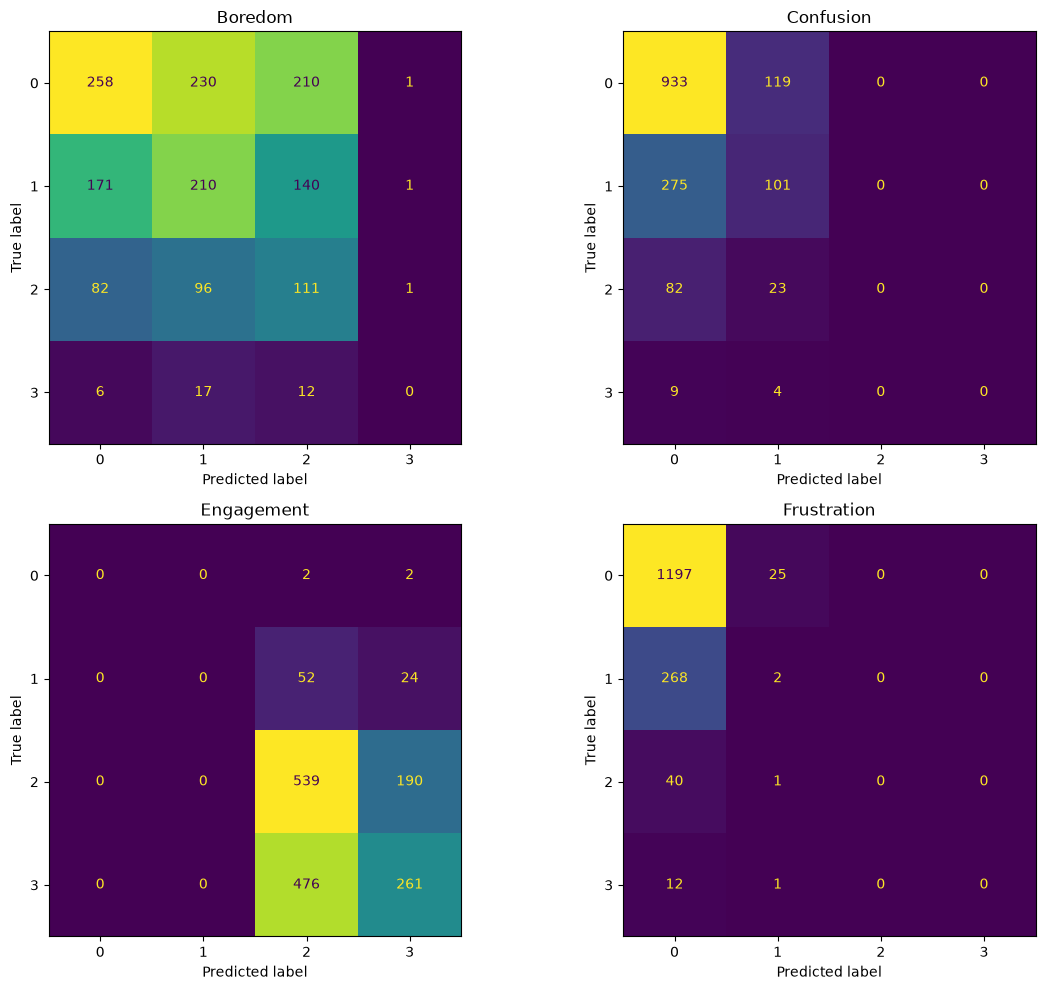


All test results saved successfully:
 - confusion_matrix_boredom.csv
 - confusion_matrix_confusion.csv
 - confusion_matrix_engagement.csv
 - confusion_matrix_frustration.csv
 - sunday_test_confusion_matrices.png
 - sunday_test_per_label_metrics.csv
 - sunday_test_predictions.csv
 - sunday_test_struggle_index.csv
 - sunday_test_summary.csv

Overall test summary:
 Test_Videos  Test_Loss  Accuracy  Macro_Precision  Macro_Recall  Macro_F1
        1546     0.9027    0.5841           0.5148        0.4847    0.4869

Per-label metrics:
      Label  Accuracy  Macro_Precision  Macro_Recall  Macro_F1
    Boredom    0.3745           0.2784        0.2885    0.2765
  Confusion    0.6688           0.2818        0.2889    0.2795
 Engagement    0.5175           0.2628        0.2734    0.2574
Frustration    0.7755           0.2145        0.2467    0.2219


In [22]:

# ============================================================
# S.U.N.D.A.Y. — SAVE FINAL TEST RESULTS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RESULTS_DIR = "sunday_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

LABELS = ["Boredom", "Confusion", "Engagement", "Frustration"]

# Make sure the test loop has already created these variables:
# y_true, y_pred, test_loss, test_accuracy

y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)

# ------------------------------------------------------------
# 1. SAVE PREDICTIONS FOR EACH TEST VIDEO
# ------------------------------------------------------------

prediction_df = pd.DataFrame()

for i, label in enumerate(LABELS):
    prediction_df[f"{label}_Actual"] = y_true[:, i]
    prediction_df[f"{label}_Predicted"] = y_pred[:, i]
    prediction_df[f"{label}_Correct"] = (
        y_true[:, i] == y_pred[:, i]
    )

prediction_df.to_csv(
    os.path.join(RESULTS_DIR, "sunday_test_predictions.csv"),
    index=False
)

# ------------------------------------------------------------
# 2. SAVE OVERALL TEST METRICS
# ------------------------------------------------------------

y_true_flat = y_true.reshape(-1)
y_pred_flat = y_pred.reshape(-1)

summary_df = pd.DataFrame([{
    "Test_Videos": len(y_true),
    "Test_Loss": float(test_loss),
    "Accuracy": accuracy_score(y_true_flat, y_pred_flat),
    "Macro_Precision": precision_score(
        y_true_flat, y_pred_flat,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    ),
    "Macro_Recall": recall_score(
        y_true_flat, y_pred_flat,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    ),
    "Macro_F1": f1_score(
        y_true_flat, y_pred_flat,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    )
}])

summary_df.to_csv(
    os.path.join(RESULTS_DIR, "sunday_test_summary.csv"),
    index=False
)

# ------------------------------------------------------------
# 3. SAVE METRICS FOR EACH LABEL
# ------------------------------------------------------------

per_label_rows = []

for i, label in enumerate(LABELS):
    per_label_rows.append({
        "Label": label,
        "Accuracy": accuracy_score(y_true[:, i], y_pred[:, i]),
        "Macro_Precision": precision_score(
            y_true[:, i], y_pred[:, i],
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "Macro_Recall": recall_score(
            y_true[:, i], y_pred[:, i],
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        ),
        "Macro_F1": f1_score(
            y_true[:, i], y_pred[:, i],
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )
    })

per_label_df = pd.DataFrame(per_label_rows)

per_label_df.to_csv(
    os.path.join(RESULTS_DIR, "sunday_test_per_label_metrics.csv"),
    index=False
)

# ------------------------------------------------------------
# 4. SAVE CONFUSION MATRICES AS PNG AND CSV
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, label in enumerate(LABELS):
    cm = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=[0, 1, 2, 3]
    )

    # Save raw confusion matrix numbers
    pd.DataFrame(
        cm,
        index=[f"Actual_{k}" for k in range(4)],
        columns=[f"Predicted_{k}" for k in range(4)]
    ).to_csv(
        os.path.join(
            RESULTS_DIR,
            f"confusion_matrix_{label.lower()}.csv"
        )
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[0, 1, 2, 3]
    )

    display.plot(
        ax=axes[i],
        colorbar=False,
        values_format="d"
    )
    axes[i].set_title(label)

plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "sunday_test_confusion_matrices.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 5. SAVE EXPERIMENTAL STRUGGLE INDEX
# ------------------------------------------------------------

struggle_index = (
    y_pred[:, 0]
    + y_pred[:, 1]
    + y_pred[:, 3]
    + (3 - y_pred[:, 2])
) / 12 * 100

struggle_df = pd.DataFrame({
    "Boredom_Predicted": y_pred[:, 0],
    "Confusion_Predicted": y_pred[:, 1],
    "Engagement_Predicted": y_pred[:, 2],
    "Frustration_Predicted": y_pred[:, 3],
    "Experimental_Struggle_Index": struggle_index
})

struggle_df.to_csv(
    os.path.join(RESULTS_DIR, "sunday_test_struggle_index.csv"),
    index=False
)

# ------------------------------------------------------------
# 6. CONFIRM SAVED FILES
# ------------------------------------------------------------

print("\nAll test results saved successfully:")
for filename in sorted(os.listdir(RESULTS_DIR)):
    print(" -", filename)

print("\nOverall test summary:")
print(summary_df.round(4).to_string(index=False))
print("\nPer-label metrics:")
print(per_label_df.round(4).to_string(index=False))
